# Supervised Learning & Model Engineering - Group project
# STEP 9: Fairness and bias audit

**Dataset:** Adult / Census Income (OpenML, `name="adult"`, `version=2`)
**Group:** Clément, Eliott Monneraie, Lucas Stefani (lead for this step: Clément, reviewed by all)
**Course reference:** Session 9 (sources of bias, demographic parity, equalized odds / equal opportunity, predictive parity, impossibility theorem, four-fifths rule, pre- / in- / post-processing mitigation, fairness-accuracy trade-off, re-audit on held-out data), Session 6 (business cost, threshold), Session 4 (bootstrap)
**Code:** `src/fairness.py`. Settings: `config.yaml`, section `fairness`. Results: `reports/fairness/`. Tests: `tests/test_fairness.py`.

### How to read this notebook
Same labels as the previous steps: **What we see**, **What we decide**, **What could invalidate it**, **Limitation**.

### The question (requirement 10)
Using the sensitive attribute of our dataset, compute and report fairness metrics with their definition, apply **one** mitigation technique, and compare performance and fairness gap **before / after on the untouched test set**.

### The rule of this step (Session 9: measure -> choose a definition -> mitigate -> re-audit)
- **Before** = the final model of STEP 6 (LightGBM, threshold 0.15), measured on the test set.
- The **fairness definition** is chosen from the cost structure **before** looking at the results (Session 9).
- The **mitigation** is chosen and tuned on the **development set only** (out-of-fold, same 5 folds as STEPS 3-5).
- **After** = the mitigated model, measured **once** on the untouched test set.

### How to run
`python -m src.fairness` (about 2 minutes: 8 weights x 5 folds of LightGBM). This notebook runs the same code.

In [1]:
# ===================== Setup =====================
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
from src.data import load_config
from src.fairness import run_fairness, save_results, log_to_mlflow

warnings.filterwarnings("ignore")
cfg = load_config()
FCFG = cfg["fairness"]
FIG_DIR = cfg["paths"]["figures_dir"]
sns.set_theme(style="whitegrid")
COLORS = {"Female": "#e7298a", "Male": "#1b9e77"}

def savefig(name: str) -> None:
    path = os.path.join(FIG_DIR, f"{name}.png")
    plt.tight_layout(); plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved: {path}")

r = run_fairness(cfg)              # before audit + trade-off curve on development + after audit (about 2 minutes)
save_results(cfg, r)
log_to_mlflow(cfg, r)
print(f"Before: STEP 6 model, threshold {r['threshold_before']:.2f} | After: weight {r['lam']:g} for wealthy women, threshold {r['threshold_after']:.2f}")
print("Check: weight 1 reproduces the STEP 6 model exactly:", r["reproduces_step6"])

/tmp/claude-0/-home-claude/f68fc5c6-3d08-5da5-90b2-5cf7429d4eee/scratchpad/repo/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026/10/19 11:48:21 INFO mlflow.tracking.fluent: Experiment with name 'adult-income' does not exist. Creating a new experiment.


Before: STEP 6 model, threshold 0.15 | After: weight 6 for wealthy women, threshold 0.24
Check: weight 1 reproduces the STEP 6 model exactly: True


---
# Part A - Which fairness definition, and why (decided before looking at the results)

**Protected attribute.** `sex` is the main attribute (decision 10). It is **not** a model input (decision 8): we kept it aside only for this audit. `race` is reported by group in Part D, without mitigation (its small groups give noisy numbers).

**The three families of definitions (Session 9)**, all computed at the business threshold:

| Definition | Question | Quantity compared between women and men |
|---|---|---|
| Demographic parity | Are both groups **called** at the same rate? | selection rate = share of people called |
| Equal opportunity | Are **wealthy** women found as often as **wealthy** men? | TPR = recall |
| Equalized odds | Equal opportunity **and** the same share of useless calls? | TPR and FPR |
| Predictive parity | Does a **call** mean the same chance of reaching a wealthy person in both groups? | PPV = precision |

**Our choice: equal opportunity.** Session 9 says: pick the definition from the cost of each error, before seeing which one the model satisfies. For the bank, a **missed wealthy prospect costs 5 useless calls** (STEP 4, X = 5). The harm for a person is to be a wealthy woman the bank never contacts, so never offered the wealth-management service. Equal opportunity protects exactly this: among wealthy people, women and men should have the same chance of being called.

**Why not the others as our target.**
- **Demographic parity** ignores who is actually wealthy. In this data 11.5% of women and 30.4% of men earn >50K: forcing equal call rates would mean calling many non-wealthy women or dropping wealthy men.
- **Predictive parity** protects the bank's advisors (a call is equally "worth it" in both groups), not the prospects. We still report it.

**Session 9 theorem (Chouldechova; Kleinberg et al.).** When base rates differ, no imperfect model can satisfy equalized odds and predictive parity at the same time. Choosing a definition is choosing which mismatch we accept. We will see it happen in Part F.

---
# Part B - Audit of the STEP 6 model (before)

In [2]:
# ===================== B.1 Metrics by sex, test set, threshold 0.15 (Fairlearn MetricFrame) =====================
fmt = {"n": "{:,.0f}", "wealthy": "{:,.0f}", "base_rate": "{:.1%}", "selection_rate": "{:.1%}",
       "tpr": "{:.1%}", "fpr": "{:.1%}", "ppv": "{:.1%}"}
print("Test set, STEP 6 model (before):")
display(r["mf_before"].by_group.style.format(fmt))
print("Development set, out-of-fold predictions of STEP 5, same threshold (stability check):")
display(r["mf_dev"].by_group.style.format(fmt))

b = r["comparison"].iloc[0]
print(f"Equal opportunity  - recall gap (men - women): {b['tpr_gap']:.1%}  (95% bootstrap interval {b['tpr_gap_ci_low']:.1%} to {b['tpr_gap_ci_high']:.1%})")
print(f"Equalized odds     - largest of the TPR and FPR gaps: {b['equalized_odds_gap']:.1%}")
print(f"Demographic parity - selection-rate ratio women / men: {b['selection_rate_ratio']:.2f}  (four-fifths rule: >= 0.80)")
print(f"Predictive parity  - precision gap: {b['ppv_gap']:.1%}")

Test set, STEP 6 model (before):


,n,wealthy,base_rate,selection_rate,tpr,fpr,ppv
group,,,,,,,
Female,"3,326",383,11.5%,19.5%,80.9%,11.5%,47.8%
Male,"6,432","1,953",30.4%,55.8%,93.9%,39.2%,51.1%


Development set, out-of-fold predictions of STEP 5, same threshold (stability check):


,n,wealthy,base_rate,selection_rate,tpr,fpr,ppv
group,,,,,,,
Female,"12,850","1,386",10.8%,20.3%,82.5%,12.7%,43.9%
Male,"26,182","7,959",30.4%,55.1%,93.2%,38.5%,51.4%


Equal opportunity  - recall gap (men - women): 12.9%  (95% bootstrap interval 8.8% to 16.7%)
Equalized odds     - largest of the TPR and FPR gaps: 27.7%
Demographic parity - selection-rate ratio women / men: 0.35  (four-fifths rule: >= 0.80)
Predictive parity  - precision gap: 3.2%


**What we see.**
- **Base rates differ a lot:** 11.5% of women vs 30.4% of men are wealthy in the test set. Session 9: a prevalence gap is not by itself unfair, but it makes the definitions conflict.
- **Equal opportunity is violated.** The model finds **81% of wealthy women (310 of 383) vs 94% of wealthy men (1,833 of 1,953)**: a gap of **12.9 points**. The 95% bootstrap interval (we resample the 9,758 test people 1,000 times, the bootstrap idea of Session 4) is **8.8 to 16.7 points**: it is far from 0, so this is not noise. On the development set (out-of-fold) the gap is 10.7 points: the same problem, not a test-set accident.
- **Demographic parity fails** clearly: 19.5% of women are called vs 55.8% of men, ratio **0.35**, far below the four-fifths rule (0.80). This mostly reflects the different base rates.
- **Equalized odds fails** too, but in the other direction for the FPR: men who are not wealthy are called much more often (39% vs 11.5%). This harms the bank (useless calls), not women.
- **Predictive parity almost holds:** a call reaches a wealthy person 48% of the time for women and 51% for men (gap 3 points). This matches STEP 7: the probabilities are well calibrated for both sexes.

**What we decide.** The problem to fix is the one our definition targets: **wealthy women are missed about twice as often as wealthy men (19% vs 6%)**.

---
# Part C - Where does the gap come from? (Session 9: sources of bias)

The model never sees `sex`. Session 9 warns that **"fairness through unawareness"** does not work when other inputs reconstruct the protected attribute (**proxy variables**). STEP 8 showed that the household signal (`relationship`, `marital-status`) is one of the strongest drivers and that **not married** people are the weakest segment. In the test set 85% of women are not married, against 38% of men. We check: inside each marital group, are wealthy women and men found equally often?

Figure saved: reports/figures/30_recall_by_sex_within_marital_status.png


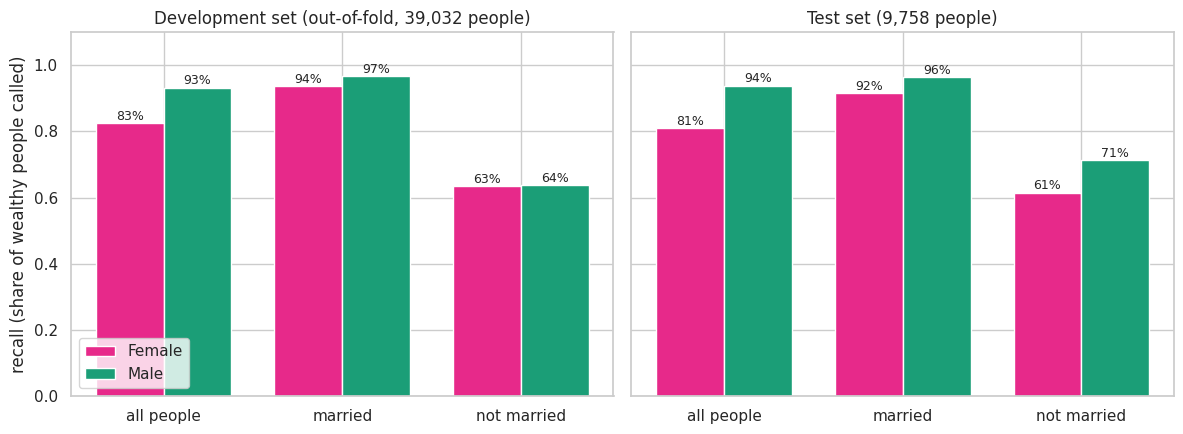

In [3]:
# ===================== C. Recall by sex INSIDE each marital-status group =====================
st = r["strata_dev"]["tpr"].unstack("sex")
st_test = r["strata_before"]["tpr"].unstack("sex")
w_dev = r["strata_dev"]["wealthy"].unstack("sex").astype(int)
w_test = r["strata_before"]["wealthy"].unstack("sex").astype(int)
table = pd.concat({"recall, development (out-of-fold)": st, "wealthy people, development": w_dev,
                   "recall, test": st_test, "wealthy people, test": w_test}, axis=1)
display(table.style.format("{:.1%}", subset=[c for c in table.columns if c[0].startswith("recall")])
             .format("{:,.0f}", subset=[c for c in table.columns if c[0].startswith("wealthy")]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
overall_dev = r["mf_dev"].by_group["tpr"]
for ax, data, overall, title in [(axes[0], st, overall_dev, "Development set (out-of-fold, 39,032 people)"),
                                 (axes[1], st_test, r["mf_before"].by_group["tpr"], "Test set (9,758 people)")]:
    cats = ["all people"] + list(data.index)
    x = np.arange(len(cats))
    for k, s in enumerate(["Female", "Male"]):
        vals = [overall[s]] + list(data[s].values)
        ax.bar(x + (k - 0.5) * 0.38, vals, width=0.38, color=COLORS[s], label=s)
        for xi, v in zip(x, vals):
            ax.text(xi + (k - 0.5) * 0.38, v + 0.01, f"{v:.0%}", ha="center", fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels(cats); ax.set_ylim(0, 1.1); ax.set_title(title)
axes[0].set_ylabel("recall (share of wealthy people called)"); axes[0].legend(loc="lower left")
savefig("30_recall_by_sex_within_marital_status")
plt.show()

**What we see.**
- On the **development set** (out-of-fold, 9,345 wealthy people), the gap **almost disappears inside each marital group**: married 93.8% (women) vs 96.7% (men); not married 63.4% vs 63.7%. The overall gap of 10.7 points comes **mostly** from the **composition**: most wealthy women are not married, and not-married wealthy people are hard to find for everyone (STEP 8).
- On the **test set** the gaps inside the groups are larger: married 91.5% vs 96.4% (4.9 points), not married 61.5% vs 71.2% (9.7 points). These groups are small (248 wealthy married women; 135 and 198 wealthy not-married people), so these differences are uncertain, but we cannot claim that the whole gap is explained by marital status.

**Interpretation (Session 9: where does unfairness come from?).**
- **Proxy variable:** `relationship` and `marital-status` carry part of the information of `sex` (a "Spouse" is a husband 9 times out of 10, STEP 2). Removing `sex` did not remove its effect.
- **Historical bias:** in the 1994 census, married women were more often secondary earners, so the label ">50K" and the household roles reflect the society of that time, not only individual ability.

On the development set the model treats similar people almost similarly: **most** of the unequal outcome comes from inputs that differ by sex, and part of it may remain inside the groups (test set). It is still a fairness problem for the bank (Session 9: audit the outcomes, not only the inputs), so we mitigate it.

---
# Part D - Secondary attribute: race (report only, decision 10)

In [4]:
# ===================== D. Metrics by race, test set, STEP 6 model =====================
display(r["mf_race"].by_group.sort_values("n", ascending=False).style.format(fmt))

,n,wealthy,base_rate,selection_rate,tpr,fpr,ppv
group,,,,,,,
White,"8,353","2,129",25.5%,45.6%,92.1%,29.8%,51.4%
Black,916,113,12.3%,24.8%,86.7%,16.1%,43.2%
Asian-Pac-Islander,311,71,22.8%,46.6%,91.5%,33.3%,44.8%
Amer-Indian-Eskimo,94,13,13.8%,37.2%,84.6%,29.6%,31.4%
Other,84,10,11.9%,21.4%,90.0%,12.2%,50.0%


**What we see.**
- Recall ranges from 85% to 92% across the five groups, with White (2,129 wealthy) at 92% and Black (113 wealthy) at 87%.
- Three groups have very few wealthy people in the test set (Amer-Indian-Eskimo 13, Other 10, Asian-Pac-Islander 71): one more or one less person found changes their recall by 1 to 10 points.

**What we decide.** We report these numbers with their sizes and do not mitigate on race (decision 10): with 10-13 wealthy people, a gap cannot be told apart from noise, and merging groups would hide opposite effects.

**Limitation.** We do not audit intersections (for example Black women): the groups would be even smaller.

---
# Part E - Mitigation, chosen on the development set

### E.1 Which lever? (Session 9: pre-processing, in-processing, post-processing)

| Lever | Example (Session 9) | Uses `sex` at decision time? | Our choice |
|---|---|---|---|
| Post-processing | `ThresholdOptimizer`: one threshold per sex | **Yes** | No: a bank deciding whom to call with a different rule for women and men is explicit use of `sex` at decision time, which decision 8 excludes (and Session 9 flags as a legal question). |
| Pre-processing | Reweighing / resampling of the training data | No | Possible, but it targets independence (demographic parity), not our definition, and gives the least control over the gap (Session 9). |
| **In-processing** | **Loss reweighted by label and group, w(y, a)** | **No** | **Yes** |

**What we do.** Session 9 writes the in-processing loss as $J_w = -\sum_i \left[ w_{y_i, a_i}\, y_i \log p_i + (1 - y_i) \log(1 - p_i) \right]$. We give a weight **`lam` to wealthy women** (y = 1, a = Female) and 1 to everyone else, and retrain the **same** LightGBM Pipeline with the **same** hyperparameters. It is the Session 6 class weight idea, applied to one (label, group) cell. Missing a wealthy woman now costs `lam` times more during training, so the model learns to give higher scores to the profiles of wealthy women, **without ever seeing `sex` as an input**. At decision time there is still **one threshold for everybody**.

**Why we search `lam` ourselves.** Fairlearn's `ExponentiatedGradient` automates a search over these weights (Session 9), but it returns a **random mixture of models** (two prospects with the same profile could get different answers) and checks its constraint on the **training predictions**, which are optimistic for boosted trees. We run the same idea with **cross-validation**: the gap is measured on out-of-fold predictions, as every other choice of the project.

**Rule fixed before running it** (config `fairness`): for each `lam` in 1, 1.5, 2, 3, 4, 6, 8, 10, we compute out-of-fold probabilities (same 5 folds), re-choose the threshold with the STEP 4 business rule, and measure the recall gap. We keep **the smallest `lam` whose out-of-fold recall gap is at most 3 points** (least intervention that reaches the target). `lam = 1` is the STEP 6 model.

,threshold,tpr_female,tpr_male,tpr_gap,cost,pr_auc,log_loss,calls,cost_vs_unweighted
lam,,,,,,,,,
1.000000,0.15,82.5%,93.2%,10.7%,"12,376",0.752,0.323,"17,035",+0.0%
1.500000,0.15,86.2%,93.9%,7.7%,"12,381",0.752,0.323,"17,658",+0.0%
2.000000,0.17,86.1%,93.1%,7.1%,"12,442",0.750,0.325,"17,347",+0.5%
3.000000,0.20,86.4%,92.2%,5.7%,"12,528",0.747,0.330,"17,007",+1.2%
4.000000,0.21,87.5%,92.2%,4.7%,"12,672",0.743,0.336,"17,277",+2.4%
6.000000,0.24,89.0%,91.5%,2.5%,"12,886",0.736,0.348,"17,269",+4.1%
8.000000,0.25,89.8%,91.8%,2.0%,"13,084",0.730,0.361,"17,671",+5.7%
10.000000,0.25,91.1%,92.4%,1.3%,"13,258",0.724,0.373,"18,229",+7.1%


Chosen on the development set: lam = 6 (smallest weight with an out-of-fold recall gap <= 3%)


Figure saved: reports/figures/31_fairness_tradeoff_curve.png


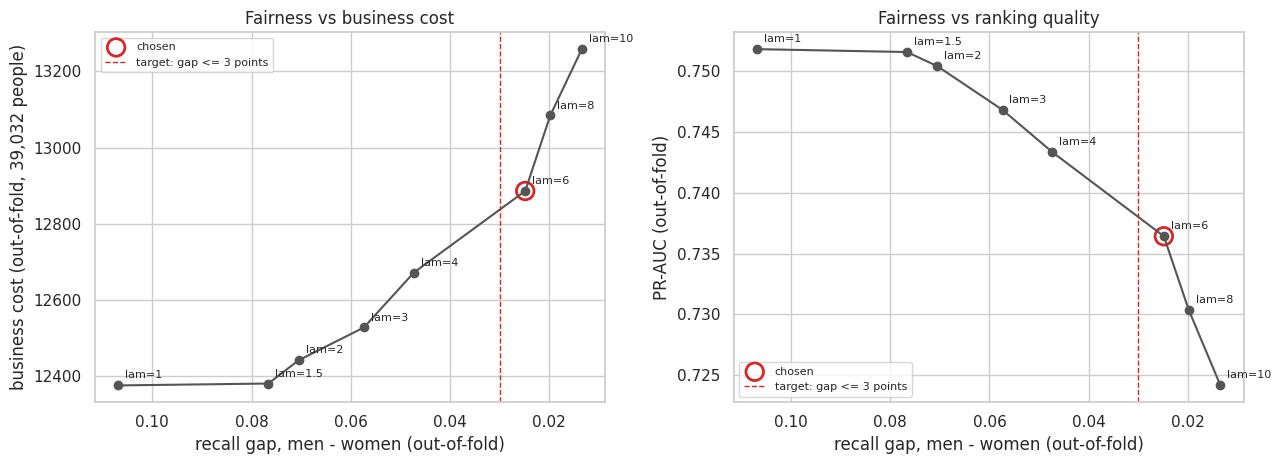

In [5]:
# ===================== E.2 Fairness-accuracy trade-off curve (development set, out-of-fold) =====================
curve = r["curve"]
display(curve.style.format({"threshold": "{:.2f}", "tpr_female": "{:.1%}", "tpr_male": "{:.1%}", "tpr_gap": "{:.1%}",
                            "cost": "{:,.0f}", "pr_auc": "{:.3f}", "log_loss": "{:.3f}", "calls": "{:,.0f}",
                            "cost_vs_unweighted": "{:+.1%}"})
                   .apply(lambda row: ["background-color: #ffe08a" if row.name == r["lam"] else "" for _ in row], axis=1))
print(f"Chosen on the development set: lam = {r['lam']:g} (smallest weight with an out-of-fold recall gap <= {FCFG['max_tpr_gap']:.0%})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, col, label in [(axes[0], "cost", "business cost (out-of-fold, 39,032 people)"), (axes[1], "pr_auc", "PR-AUC (out-of-fold)")]:
    ax.plot(curve["tpr_gap"], curve[col], "o-", color="#555555")
    for lam, row in curve.iterrows():
        ax.annotate(f"lam={lam:g}", (row["tpr_gap"], row[col]), textcoords="offset points", xytext=(5, 5), fontsize=8)
    ch = curve.loc[r["lam"]]
    ax.scatter([ch["tpr_gap"]], [ch[col]], s=160, facecolors="none", edgecolors="#d62728", linewidths=2, label="chosen")
    ax.axvline(FCFG["max_tpr_gap"], color="#d62728", ls="--", lw=1, label="target: gap <= 3 points")
    ax.set_xlabel("recall gap, men - women (out-of-fold)"); ax.set_ylabel(label); ax.invert_xaxis(); ax.legend(fontsize=8)
axes[0].set_title("Fairness vs business cost"); axes[1].set_title("Fairness vs ranking quality")
savefig("31_fairness_tradeoff_curve")
plt.show()

**What we see** (development set, out-of-fold: no test data used).
- As `lam` grows, the recall gap shrinks steadily: **10.7 points** (lam = 1) -> 7.7 -> 7.1 -> 5.7 -> 4.7 -> **2.5 points (lam = 6)** -> 2.0 -> 1.3 (lam = 10).
- It has a price, as Session 9 announces: the business cost rises from 12,376 to **12,886 at lam = 6 (+4.1%)**, the PR-AUC falls from 0.752 to **0.736**, and the log-loss rises (0.323 -> 0.348): the probabilities become less precise.
- The threshold chosen by the business rule moves up (0.15 -> 0.24): the weights push all scores up, so the same business rule cuts higher.

**What we decide.** Following the rule fixed in advance, **lam = 6** (decision 61): the first weight with an out-of-fold gap of at most 3 points (2.5). Going further (lam = 10) would buy 1.2 points of gap for 3 more points of cost.

**What could invalidate it.** A different target than 3 points: it is a business and ethical choice (Session 9), and the curve shows its price for every option.

---
# Part F - Before / after, on the untouched test set

model,before (STEP 6 model),after (lam = 6)
threshold,0.150,0.240
pr_auc,0.763,0.753
log_loss,0.319,0.342
brier,0.102,0.110
ece,0.013,0.062
recall,91.7%,91.1%
precision,50.6%,49.4%
calls,"4,238","4,303"
cost,"3,060","3,221"
tpr_gap,12.9%,4.3%


Figure saved: reports/figures/32_fairness_before_after_test.png


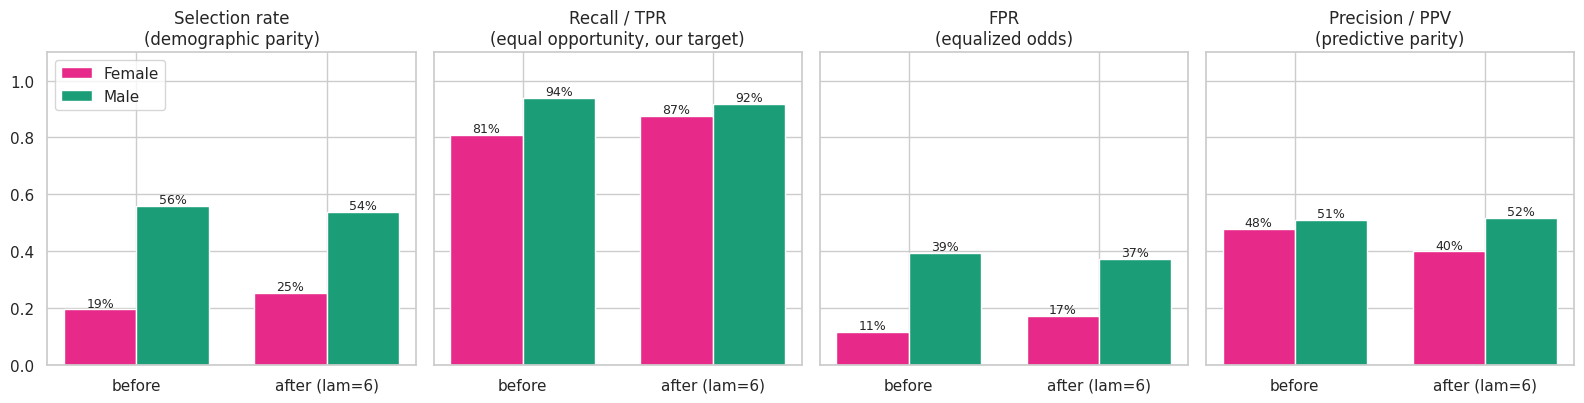

In [6]:
# ===================== F. Re-audit on the test set (measured once) =====================
comp = r["comparison"].T
pct = ["recall", "precision", "tpr_gap", "fpr_gap", "equalized_odds_gap", "ppv_gap", "tpr_gap_ci_low", "tpr_gap_ci_high"]
display(comp.style.format(lambda v: f"{v:.1%}" if isinstance(v, float) and abs(v) < 1 else (f"{v:,.3f}" if isinstance(v, float) else v), subset=pd.IndexSlice[pct, :])
               .format("{:,.3f}", subset=pd.IndexSlice[["threshold", "pr_auc", "log_loss", "brier", "ece", "selection_rate_ratio"], :])
               .format("{:,.0f}", subset=pd.IndexSlice[["calls", "cost"], :]))
by = pd.concat({"before": r["mf_before"].by_group, "after": r["mf_after"].by_group}, names=["model"])
display(by.style.format(fmt))

fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharey=True)
for ax, (m, label) in zip(axes, [("selection_rate", "Selection rate\n(demographic parity)"), ("tpr", "Recall / TPR\n(equal opportunity, our target)"),
                                 ("fpr", "FPR\n(equalized odds)"), ("ppv", "Precision / PPV\n(predictive parity)")]):
    x = np.arange(2)
    for k, s in enumerate(["Female", "Male"]):
        vals = [r["mf_before"].by_group.loc[s, m], r["mf_after"].by_group.loc[s, m]]
        ax.bar(x + (k - 0.5) * 0.38, vals, width=0.38, color=COLORS[s], label=s)
        for xi, v in zip(x, vals):
            ax.text(xi + (k - 0.5) * 0.38, v + 0.01, f"{v:.0%}", ha="center", fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels(["before", f"after (lam={r['lam']:g})"]); ax.set_title(label); ax.set_ylim(0, 1.1)
axes[0].legend(loc="upper left")
savefig("32_fairness_before_after_test")
plt.show()

**What we see** (test set, 9,758 people, measured once).

*Our target, equal opportunity:*
- Wealthy women found: **310 -> 335 of 383 (81% -> 87%)**. Wealthy men found: 1,833 -> 1,792 of 1,953 (94% -> 92%).
- Recall gap: **12.9 -> 4.3 points**, 95% bootstrap interval **0.9 to 7.5 points** (before: 8.8 to 16.7). The two intervals do not overlap: the reduction is real. The test gap (4.3) is a bit above the out-of-fold gap that chose `lam` (2.5): only 383 wealthy women in the test set, so one point of their recall is about 4 people.

*What it costs (Session 9: disclose what was traded away):*
- **Business cost 3,060 -> 3,221 (+5.3%)**, in line with the development estimate (+4.1%). Overall recall 91.7% -> 91.1%, calls 4,238 -> 4,303.
- **Ranking:** PR-AUC 0.763 -> 0.753 (-0.010).
- **Probabilities:** ECE 0.013 -> **0.062**, Brier 0.102 -> 0.110. The weights push the scores of the profiles of wealthy women up, so the probabilities are **no longer calibrated**: the STEP 7 conclusion ("probabilities usable as they are") holds for the STEP 6 model only.
- **Predictive parity gets worse:** precision for women 47.8% -> **39.9%** (gap 3 -> 12 points). Calling more women with a lower base rate means more useless calls among them (338 -> 505). **This is the Session 9 theorem happening on our data**: with different base rates, moving towards equal opportunity moves away from predictive parity.

*Other definitions:* the selection-rate ratio improves (0.35 -> 0.47) but stays far below 0.8; the FPR gap shrinks (27.7 -> 20.1 points) because more non-wealthy women and fewer non-wealthy men are called.

*Inside the marital groups:* see the table below. The mitigation helps not-married wealthy women (61.5% -> 72.6%) and married wealthy women (91.5% -> 95.6%).

In [7]:
# ===================== F.2 Inside each marital-status group, test set =====================
inside = pd.concat({"before": r["strata_before"]["tpr"].unstack("sex"), "after": r["strata_after"]["tpr"].unstack("sex")}, axis=1)
display(inside.style.format("{:.1%}"))

---
# Part G - Answer to requirement 10, and our recommendation

**Metrics and definitions.** On the test set, the STEP 6 model violates **equal opportunity** (recall 81% for wealthy women vs 94% for wealthy men, gap 12.9 points, 95% interval 8.8-16.7), fails demographic parity (selection-rate ratio 0.35) and equalized odds, and almost satisfies predictive parity (precision gap 3 points). The gap comes **mainly** from **proxies**, not from `sex` itself (not an input): marital status and household role, linked to sex in the 1994 census; on the test set a smaller part remains inside the marital groups.

**Mitigation.** In-processing reweighting of the loss by label and group (weight 6 on wealthy women), chosen on the development set with cross-validation. On the untouched test set: recall gap **12.9 -> 4.3 points**, **25 more wealthy women found**, for **+5.3% business cost**, PR-AUC -0.010, probabilities no longer calibrated, and a wider precision gap.

**What we decide** (decision 63). The **STEP 6 model stays our final model**: all the results of STEPS 6-8 refer to it. The operating point between fairness and cost is a business and ethical decision of the bank (Session 9). **If the bank makes equal opportunity a requirement, we recommend the mitigated model**, because equal opportunity is the definition that matches the harm we care about (a wealthy woman never offered the service), and its price is moderate and fully disclosed. Two conditions before any real use:
1. its probabilities must be **read as a ranking**, not as percentages, or be recalibrated on out-of-fold predictions (STEP 7 method) before an advisor reads "47%";
2. the bank's compliance team must accept that `sex` is **collected for training** (never for the decision).

**Limitations.**
- `sex` is binary in the census; other identities are not represented.
- The label is the 1994 income: **historical and label bias** stay in the data whatever the model does.
- Small groups (race, not-married women in the test set) give wide intervals.
- The target "gap <= 3 points" is our business judgement; the trade-off curve (Part E) gives the price of any other choice.

---
# Part H - Model card, fairness section (Session 9: report by group, name the definition, disclose the trade-off)

| Item | Value |
|---|---|
| Protected attribute | `sex` (not a model input); `race` reported only |
| Definition prioritised | **Equal opportunity** (equal recall for wealthy women and men), because a missed wealthy prospect is the costly error (X = 5) |
| STEP 6 model, test | recall women 81% / men 94% (gap 12.9 points); precision 48% / 51%; selection rate 20% / 56% |
| Mitigation | In-processing: loss weight 6 on wealthy women, chosen on development out-of-fold (gap <= 3 points), one threshold for everybody (0.24) |
| Mitigated model, test | recall women 87% / men 92% (gap 4.3 points); precision 40% / 52%; selection rate 25% / 54% |
| Traded away | +5.3% business cost, PR-AUC 0.763 -> 0.753, calibration (ECE 0.013 -> 0.062), predictive parity (precision gap 3 -> 12 points) |
| Not for | Populations far from the 1994 US census without a new audit; reading the mitigated probabilities as exact percentages |

---
# Part I - Decisions log for STEP 9 (copied into DECISIONS.md)

| # | Decision | Where |
|---|---|---|
| 56 | Audit with Fairlearn `MetricFrame` by `sex` at the business threshold: size, base rate, selection rate, TPR, FPR, PPV; one summary number per definition; 95% bootstrap interval for the recall gap | `group_metrics`, `gap_summary`, `bootstrap_tpr_gap` |
| 57 | Definition prioritised: **equal opportunity**, chosen from the cost structure before the results (X = 5); demographic parity, equalized odds and predictive parity reported, not targeted | notebook 09 A |
| 58 | Before (test): recall gap 12.9 points (8.8-16.7), development 10.7; selection ratio 0.35; precision gap 3 points | notebook 09 B |
| 59 | Source of the gap: proxies (marital status, household role) + historical bias; inside each marital group the gap is 0.3-2.9 points on development, 4.9 and 9.7 points on test (small groups): most of the gap, not necessarily all | `recall_within_strata`, notebook 09 C |
| 60 | `race`: reported by group with sizes, no mitigation (10-113 wealthy people in the minority groups) | notebook 09 D |
| 61 | Mitigation: in-processing reweighting w(y, a), weight 6 on wealthy women, chosen on development out-of-fold (smallest weight with gap <= 3 points); no post-processing (would use `sex` at decision time, decision 8) | `tradeoff_curve`, `choose_lambda` |
| 62 | After (test): recall gap 4.3 points (0.9-7.5), +25 wealthy women found, cost +5.3%, PR-AUC -0.010, ECE 0.013 -> 0.062, precision gap 3 -> 12 points (Session 9 theorem) | `reports/fairness/before_after_test.csv` |
| 63 | STEP 6 model stays the final model; if the bank requires equal opportunity, we recommend the mitigated model, read as a ranking or recalibrated, with compliance approval for using `sex` in training | notebook 09 G-H |